## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [ ]:
# @title Ingrese datos
nombre_estudiante = "Rafael Esteban Henao Prieto"
carnet= "1000113957"


## 1) Descripción del problema **[1 pts]**
En este trabajo abordo dos problemas de una empresa que necesita organizar mejor su operación técnica: por un lado, atender tareas según su prioridad y, por otro, conectar seis dispositivos físicos usando la menor cantidad posible de cable.

Para la gestión de tareas, tengo un listado inicial con códigos, descripciones y niveles de prioridad (donde un número mayor significa mayor urgencia). El objetivo es organizarlas usando una cola de prioridad máxima implementada con un Max-Heap desde cero, consultar el arreglo y el árbol resultante, procesar las dos tareas más urgentes extrayéndolas del heap y luego insertar una nueva tarea crítica (`T07` con prioridad 12) manteniendo la propiedad del heap sin usar. o eso diria yo.

## 2) Requerimientos **[2 pts]**

Lista requerimientos **funcionales** y **no funcionales**.

###Requisitos funcionales

* Cargar las tareas iniciales (`T01` a `T06`) con su código, nombre y prioridad, y mostrar el arreglo inicial.
* Implementar `MAX-HEAPIFY` y `BUILD-MAX-HEAP` para construir el Max-Heap y mostrar tanto el arreglo resultante como la representación gráfica del árbol.
* Implementar `EXTRACT-MAX` para sacar las dos tareas de mayor prioridad una por una, mostrando en cada paso la tarea atendida y cómo queda el heap.
* Insertar la tarea `T07` (Falla en sistema contra incendios, prioridad 12) conservando la estructura de Max-Heap y mostrar el resultado actualizado.
* Registrar los seis dispositivos con sus coordenadas `(X, Y)`, graficar su posición y calcular la distancia entre todas las parejas posibles como peso de cada arista.
* Implementar manualmente el algoritmo de Kruskal (ordenando aristas por peso, seleccionando las de menor costo y evitando ciclos) hasta conectar los 6 dispositivos con 5 aristas.
* Mostrar las conexiones elegidas del MST, la longitud total de cable y una gráfica final solo con las conexiones del MST, los pesos y el total de cable.

###Requisitos no funcionales

* Todo el desarrollo debe ir dentro de un único notebook llamado `parcial_prioridad_mst.ipynb` y ejecutado completo.
* No se permite usar `heapq` para el manejo del heap ni funciones de librerías que calculen el MST directamente.
* El código debe ser claro y legible en su ejecución, con salidas visibles para cada paso solicitado.
* El flujo de trabajo debe hacerse en Git/GitHub creando la rama `parcial-prioridad-mst`, abriendo un Pull Request hacia `main` con descripción y pantallazos del Max-Heap y del MST final, y haciendo el merge a `main`.


## 3) Historias de usuario **[2 pts]**

**Historia 1: Armar el heap**
Como estudiante, quiero cargar las tareas y armar el Max-Heap para ver si quedó bien ordenado según la prioridad.

*Criterios: se cargan T01 a T06, se usa `BUILD-MAX-HEAP` y se muestra el arreglo y el árbol.

**Historia 2: Sacar las tareas más urgentes**
Como estudiante, quiero sacar las dos tareas de mayor prioridad para atender lo más urgente primero y ver cómo queda el heap.

*Criterios: se ejecuta `EXTRACT-MAX` dos veces, mostrando la tarea que sale y el heap después de cada una.

**Historia 3: Meter T07**
Como estudiante, quiero agregar la tarea T07 con prioridad 12 para que quede bien ubicada sin usar `heapq`.

* Criterios: se inserta T07, se mantiene la propiedad del Max-Heap y se muestra el heap final.

**Historia 4: Conectar dispositivos con menos cable**
Como estudiante, quiero hallar el MST de los dispositivos A-F para saber cuál es la menor cantidad de cable necesaria.

*Criterios: se calculan distancias, se aplica Kruskal manual sin ciclos con 5 aristas, se muestra el total de cable y la gráfica final.


## 4) Diagramas de flujo **[5 pts]**
Incluye el diagrama que muestre el proceso general

Adjunta imagen y descríbelo claramente.
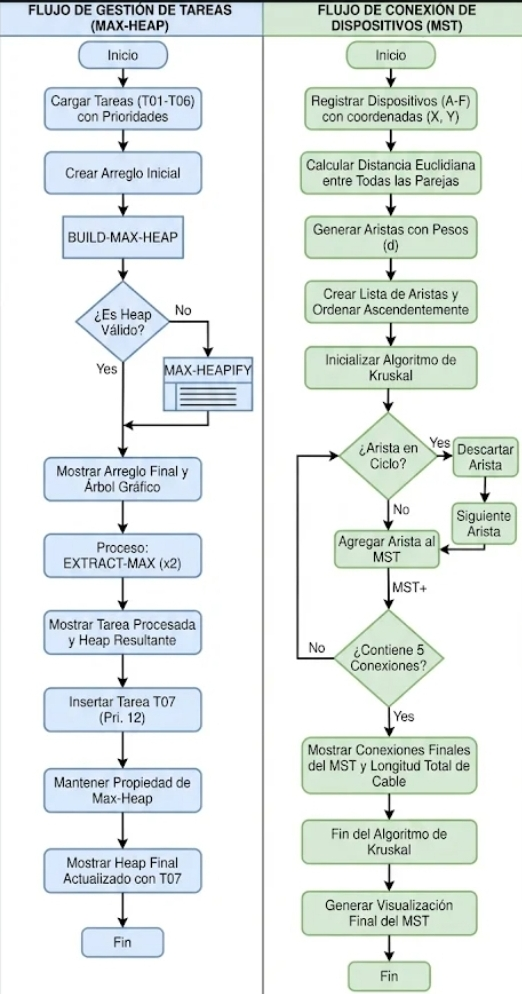

### 5) Análisis de complejidad **[15 pts]**
Incluye:

La verdad no estoy 100% seguro de si lo explico perfecto, pero esto es lo que entiendo del costo de cada parte:

* **BUILD-MAX-HEAP:** toma tiempo $O(n)$, donde $n$ es la cantidad de tareas, porque aunque `MAX-HEAPIFY` cuesta $O(\log n)$, al hacerlo desde abajo en el árbol el total queda lineal.
* **EXTRACT-MAX e insertar:** ambas cuestan $O(\log n)$ porque en el peor caso recorren desde abajo hasta la raíz o viceversa, o sea la altura del árbol.
* **Kruskal:** como hay $V$ dispositivos (acá 6), se revisan pares de aristas y se ordenan, lo que da $O(E \log E)$ o $O(V^2 \log V)$.



###Funciones T(n):
* Construir heap: $T(n) \approx c_1 \cdot n$
* Sacar o insertar: $T(n) \approx c_2 \cdot \log n$
* Kruskal: $T(V) \approx c_3 \cdot V^2 \log V$



###Mejor y peor caso:
En el heap el mejor y el peor caso siguen el mismo orden asintótico ($O(\log n)$ en sacar e insertar, $O(n)$ al construir). En Kruskal, el peor caso es cuando hay más conexiones posibles que ordenar y revisar. Si lo graficamos, $O(\log n)$ crece muy poquito, $O(n)$ sube parejo y $O(V^2 \log V)$ sube mucho más rápido conforme crecen los nodos.

## 6) Código funcional **[15 pts]**
Incluye tu implementación completa.


In [ ]:
import matplotlib.pyplot as plt
import math

tareas = [
    ("T01", "Configurar servidor", 6),
    ("T02", "Reparar sensor", 10),
    ("T03", "Actualizar software", 4),
    ("T04", "Revisar camara", 8),
    ("T05", "Generar respaldo", 3),
    ("T06", "Configurar alarma", 7)
]

print("Arreglo inicial:")
print(tareas)

def max_heapify(A, n, i):
    mayor = i
    izq = 2 * i + 1
    der = 2 * i + 2
    
    if izq < n and A[izq][2] > A[mayor][2]:
        mayor = izq
    if der < n and A[der][2] > A[mayor][2]:
        mayor = der
        
    if mayor != i:
        A[i], A[mayor] = A[mayor], A[i]
        max_heapify(A, n, mayor)

def build_max_heap(A):
    n = len(A)
    for i in range(n // 2 - 1, -1, -1):
        max_heapify(A, n, i)

heap = tareas.copy()
build_max_heap(heap)

print("\nMax-Heap resultante:")
print(heap)

def dibujar_arbol(arr):
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.axis('off')
    n = len(arr)
    coords = {}
    
    for i in range(n):
        nivel = int(math.log2(i + 1))
        pos_nivel = i - (2**nivel - 1)
        total_nivel = 2**nivel
        x = (pos_nivel + 0.5) / total_nivel
        y = 1 - (nivel * 0.25)
        coords[i] = (x, y)
        
    for i in range(n):
        izq = 2 * i + 1
        der = 2 * i + 2
        if izq < n:
            ax.plot([coords[i][0], coords[izq][0]], [coords[i][1], coords[izq][1]], 'k-')
        if der < n:
            ax.plot([coords[i][0], coords[der][0]], [coords[i][1], coords[der][1]], 'k-')
            
    for i, (x, y) in coords.items():
        texto = f"{arr[i][0]}\n({arr[i][2]})"
        ax.text(x, y, texto, ha='center', va='center', bbox=dict(boxstyle='circle,pad=0.4', facecolor='lightblue', edgecolor='black'))
        
    plt.title("Arbol Max-Heap")
    plt.show()

dibujar_arbol(heap)

## 7) Tests aplicados **[15 pts]**

In [ ]:
```python
# Pruebas rapidas del Max-Heap y extracciones
assert heap[0][2] >= max(x[2] for x in heap)
assert t1[0] == "T02" and t1[2] == 10
assert t2[0] == "T04" and t2[2] == 8
assert any(x[0] == "T07" and x[2] == 12 for x in heap)

# Pruebas del MST con Kruskal
assert len(mst) == len(dispositivos) - 1
assert len(mst) == 5
assert costo_total > 0
assert all(p > 0 for _, _, p in mst)

```